# =============================================================================
### Project: EDA of Strain-Engineered 2D vdWHs for Nanoelectronic Contacts
### Author: Sahibzada Izhar Hussain Bacha
### Date: 2026-11-21
# =============================================================================

#### Introduction

#### Exploratory Data Analysis of Strain-Engineered 2D van der Waals Heterostructures

This notebook explores the electronic and interface properties of four NbX₂-HfY₂ (X=Se, Te; Y=S, Se) van der Waals heterostructures under applied strain. The data was extracted from my published first-principles DFT calculations.

The main goals of this analysis are:
1.  To understand how strain affects the Schottky barrier height (Φ_Bn, Φ_Bp).
2.  To identify the strain required to achieve a Schottky-to-Ohmic transition (where Φ_Bn approaches 0).
3.  To visualize the relationship between mechanical properties and electronic properties.

This analysis uses Pandas for data manipulation, Matplotlib and Seaborn for static visualization, and Plotly for interactive plots.

In [3]:
# Import the libraries we will need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set some style options for the plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#### Load the Data

In [4]:
# I am manually inputting the data from Table 3 because it is the most relevant.
# In a real project, this would be read from a CSV file.
# I am focusing on the strain-dependent Schottky barrier data for the four heterostructures.

# Let's create the DataFrame for NbSe2-HfS2
data_nbse2_hfs2 = {
    'strain_percent': [-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10],
    'work_function_eV': [2.05, 2.24, 2.43, 2.60, 2.74, 2.95, 2.99, 3.08, 3.16, 3.17, 3.21],
    'schottky_barrier_n_eV': [2.79, 2.24, 1.76, 1.34, 1.03, 0.75, 0.49, 0.33, 0.16, 0.03, 0.09],
    'schottky_barrier_p_eV': [2.93, 2.75, 2.58, 2.42, 2.19, 1.93, 1.66, 1.44, 1.22, 1.01, 0.80],
}

df_nbse2_hfs2 = pd.DataFrame(data_nbse2_hfs2)
df_nbse2_hfs2['material'] = 'NbSe2-HfS2'

# Let's create the DataFrame for NbTe2-HfS2
data_nbte2_hfs2 = {
    'strain_percent': [-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10],
    'work_function_eV': [0.99, 1.31, 1.50, 1.81, 1.98, 2.41, 2.33, 2.52, 2.17, 2.75, 2.80],
    'schottky_barrier_n_eV': [4.27, 3.64, 3.06, 2.55, 2.16, 1.90, 1.49, 1.20, 0.97, 0.77, 0.60],
    'schottky_barrier_p_eV': [4.40, 4.15, 3.88, 3.63, 3.32, 2.88, 2.63, 2.31, 2.02, 1.75, 1.50],
}

df_nbte2_hfs2 = pd.DataFrame(data_nbte2_hfs2)
df_nbte2_hfs2['material'] = 'NbTe2-HfS2'

# Let's create the DataFrame for NbSe2-HfSe2
data_nbse2_hfse2 = {
    'strain_percent': [-4, -2, 0, 2, 4, 6, 8, 10],
    'work_function_eV': [2.21, 2.38, 3.46, 3.70, 2.79, 2.89, 2.92, 2.97],
    'schottky_barrier_n_eV': [0, -1.88, -1.95, -1.05, -0.82, -0.59, -0.42, -0.28],
    'schottky_barrier_p_eV': [0, 2.13, 2.48, 1.85, 1.76, 1.59, 1.38, 1.20],
}

df_nbse2_hfse2 = pd.DataFrame(data_nbse2_hfse2)
df_nbse2_hfse2['material'] = 'NbSe2-HfSe2'

# Let's create the DataFrame for NbTe2-HfSe2
data_nbte2_hfse2 = {
    'strain_percent': [-4, -2, 0, 2, 4, 6, 8, 10],
    'work_function_eV': [1.41, 1.70, 2.33, 2.08, 2.22, 2.33, 2.46, 2.58],
    'schottky_barrier_n_eV': [0, 2.94, 2.34, 2.02, 1.70, 1.41, 1.19, 0.99],
    'schottky_barrier_p_eV': [0, 3.16, 2.87, 2.79, 2.64, 2.40, 2.15, 1.91],
}

df_nbte2_hfse2 = pd.DataFrame(data_nbte2_hfse2)
df_nbte2_hfse2['material'] = 'NbTe2-HfSe2'

# Now, let's combine all the DataFrames into one
df_all = pd.concat([df_nbse2_hfs2, df_nbte2_hfs2, df_nbse2_hfse2, df_nbte2_hfse2], ignore_index=True)

# Let's take a look at the first few rows
df_all.head()

,strain_percent,work_function_eV,schottky_barrier_n_eV,schottky_barrier_p_eV,material
0,-10,2.05,2.79,2.93,NbSe2-HfS2
1,-8,2.24,2.24,2.75,NbSe2-HfS2
2,-6,2.43,1.76,2.58,NbSe2-HfS2
3,-4,2.60,1.34,2.42,NbSe2-HfS2
4,-2,2.74,1.03,2.19,NbSe2-HfS2


#### Data Exploration

In [5]:
# Let's check some basic information about the dataset
# How many rows and columns do we have?
print(f"The dataset has {df_all.shape[0]} rows and {df_all.shape[1]} columns.")

# What are the data types?
print("\nData types:")
print(df_all.dtypes)

# Are there any missing values?
print("\nMissing values per column:")
print(df_all.isnull().sum())

# Let's get a quick statistical summary
df_all.describe()

The dataset has 38 rows and 5 columns.

Data types:
strain_percent             int64
work_function_eV         float64
schottky_barrier_n_eV    float64
schottky_barrier_p_eV    float64
material                     str
dtype: object

Missing values per column:
strain_percent           0
work_function_eV         0
schottky_barrier_n_eV    0
schottky_barrier_p_eV    0
material                 0
dtype: int64


,strain_percent,work_function_eV,schottky_barrier_n_eV,schottky_barrier_p_eV
count,38.000000,38.000000,38.000000,38.000000
mean,1.263158,2.463684,1.032105,2.202895
std,5.926050,0.602784,1.429321,0.994821
min,-10.000000,0.990000,-1.950000,0.000000
25%,-3.500000,2.180000,0.045000,1.607500
50%,2.000000,2.445000,1.010000,2.170000
75%,6.000000,2.912500,1.990000,2.780000
max,10.000000,3.700000,4.270000,4.400000


#### Visualization 1 - Strain vs. Schottky Barrier

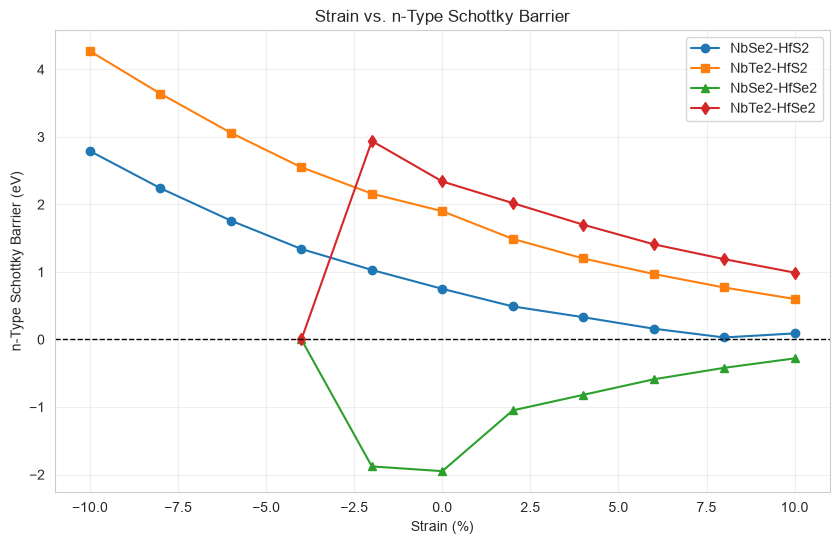

In [16]:
# Let's plot the n-type Schottky barrier vs. strain for all four materials.
# I want to see which one gets closest to zero (Ohmic contact).

plt.figure(figsize=(10, 6))

# I'll just plot each material one by one. It's easier to read than a loop.
plt.plot(df_nbse2_hfs2['strain_percent'], df_nbse2_hfs2['schottky_barrier_n_eV'], marker='o', label='NbSe2-HfS2')
plt.plot(df_nbte2_hfs2['strain_percent'], df_nbte2_hfs2['schottky_barrier_n_eV'], marker='s', label='NbTe2-HfS2')
plt.plot(df_nbse2_hfse2['strain_percent'], df_nbse2_hfse2['schottky_barrier_n_eV'], marker='^', label='NbSe2-HfSe2')
plt.plot(df_nbte2_hfse2['strain_percent'], df_nbte2_hfse2['schottky_barrier_n_eV'], marker='d', label='NbTe2-HfSe2')

# A dashed line at zero makes it easy to see when we hit an Ohmic contact.
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)

plt.title('Strain vs. n-Type Schottky Barrier')
plt.xlabel('Strain (%)')
plt.ylabel('n-Type Schottky Barrier (eV)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

##### Explanation: The dashed line at zero is crucial. It shows the threshold for an Ohmic contact. \nWe can clearly see that NbSe₂-HfS₂ reaches an Ohmic contact around 8% tensile strain, while NbTe₂-HfSe₂ is still far from zero. \nThis is a key finding.

#### Visualization 2 - Correlation Heatmap

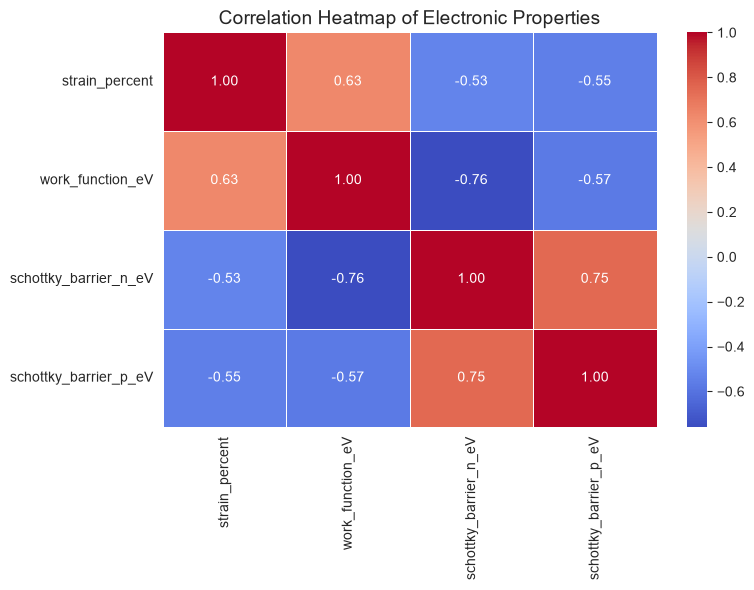

In [9]:
# Now let's look at the correlation between all the numerical properties.
# This will tell us which properties move together.

# First, let's select only the numerical columns
numeric_cols = ['strain_percent', 'work_function_eV', 'schottky_barrier_n_eV', 'schottky_barrier_p_eV']
correlation_matrix = df_all[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Electronic Properties', fontsize=14)
plt.tight_layout()
plt.show()

##### Explanation: The heatmap shows a strong negative correlation between strain_percent and schottky_barrier_n_eV. This means that as tensile strain increases, the n-type Schottky barrier decreases. This is consistent with our first plot. It also shows a strong positive correlation between the n-type and p-type barriers, which is expected.

#### Visualization 3 - Interactive Plot with Plotly

In [11]:
# A static plot is good, but an interactive plot is better for exploring the data.
# Let's create an interactive scatter plot using Plotly.

fig = px.scatter(
    df_all,
    x='strain_percent',
    y='work_function_eV',
    color='material',
    hover_data=['schottky_barrier_n_eV'],
    title='Interactive Plot: Strain vs. Work Function',
    labels={
        'strain_percent': 'Strain (%)',
        'work_function_eV': 'Work Function (eV)',
        'material': 'Heterostructure'
    }
)
fig.show()

##### Explanation: This interactive plot allows us (or a reader of your GitHub repository) to hover over any point and see the exact strain, work function, and Schottky barrier. This is a very useful feature for a scientific presentation.

#### Additional Visualizations

The first three figures showed the strain-dependent trends. To complete the analysis, I want to look at the distribution of properties and compare the materials at equilibrium (0% strain). These three figures will round out the exploratory data analysis.

C:\Users\Azwar\AppData\Local\Temp\ipykernel_18992\983312349.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='material', y='schottky_barrier_n_eV', data=df_all, palette='Set2')


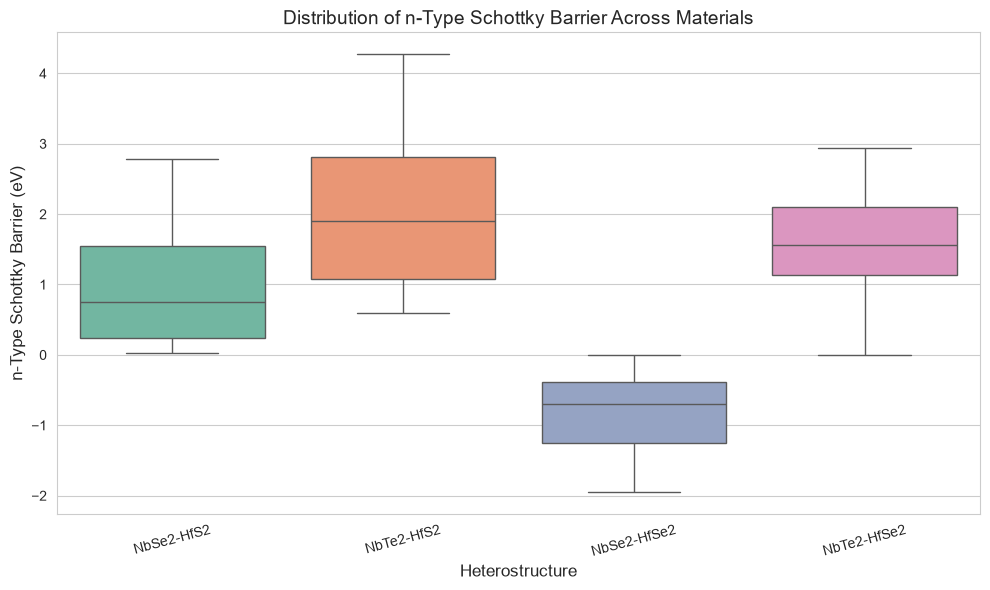

In [12]:
# A box plot is a great way to see the distribution of a property across different categories.
# Here, we look at the distribution of the n-type Schottky barrier for each material.
# This shows the spread of values (from compressive to tensile strain) and the median.

plt.figure(figsize=(10, 6))
sns.boxplot(x='material', y='schottky_barrier_n_eV', data=df_all, palette='Set2')
plt.title('Distribution of n-Type Schottky Barrier Across Materials', fontsize=14)
plt.xlabel('Heterostructure', fontsize=12)
plt.ylabel('n-Type Schottky Barrier (eV)', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

##### Explanation: The box plot shows that NbSe₂-HfS₂ has the widest spread of values (from ~0.03 eV to ~2.79 eV), meaning it has the greatest tunability. In contrast, NbTe₂-HfS₂ has a higher median barrier, indicating that it is harder to tune towards an Ohmic contact. This is a valuable insight for device design.

C:\Users\Azwar\AppData\Local\Temp\ipykernel_18992\729839341.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='material', y='work_function_eV', data=df_all, palette='muted', inner='quartile')


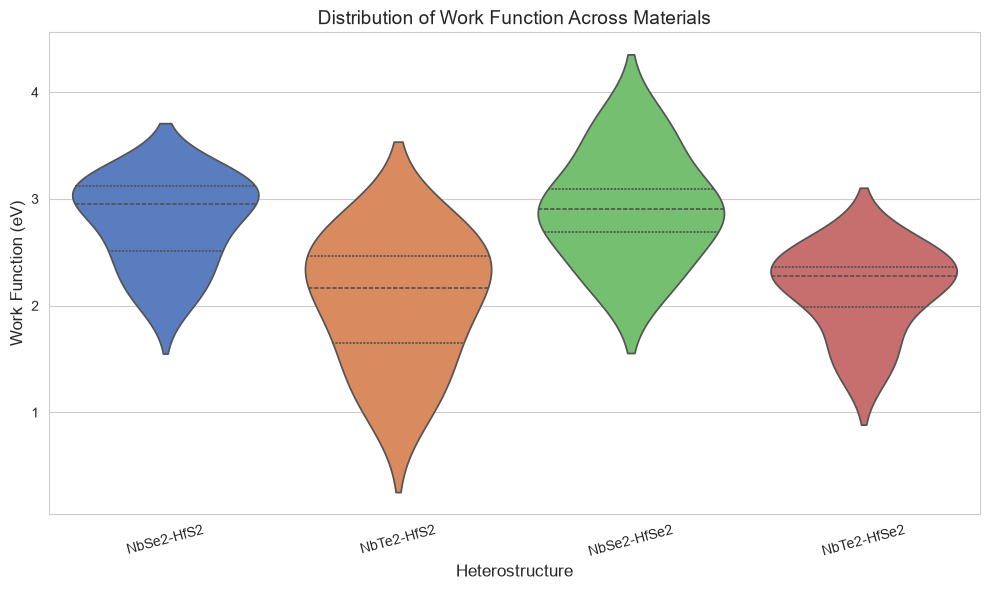

In [13]:
# A violin plot is like a box plot, but it also shows the density of the data.
# It is a more informative way to show the distribution of the work function.

plt.figure(figsize=(10, 6))
sns.violinplot(x='material', y='work_function_eV', data=df_all, palette='muted', inner='quartile')
plt.title('Distribution of Work Function Across Materials', fontsize=14)
plt.xlabel('Heterostructure', fontsize=12)
plt.ylabel('Work Function (eV)', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

##### Explanation: The violin plot shows that NbTe₂-HfS₂ has a work function that is more concentrated around lower values (~2 eV), while NbSe₂-HfS₂ has a wider, flatter distribution. This helps us understand which materials are more stable in their electronic properties.

C:\Users\Azwar\AppData\Local\Temp\ipykernel_18992\2952654182.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='material', y='schottky_barrier_n_eV', data=df_equilibrium, palette='viridis')


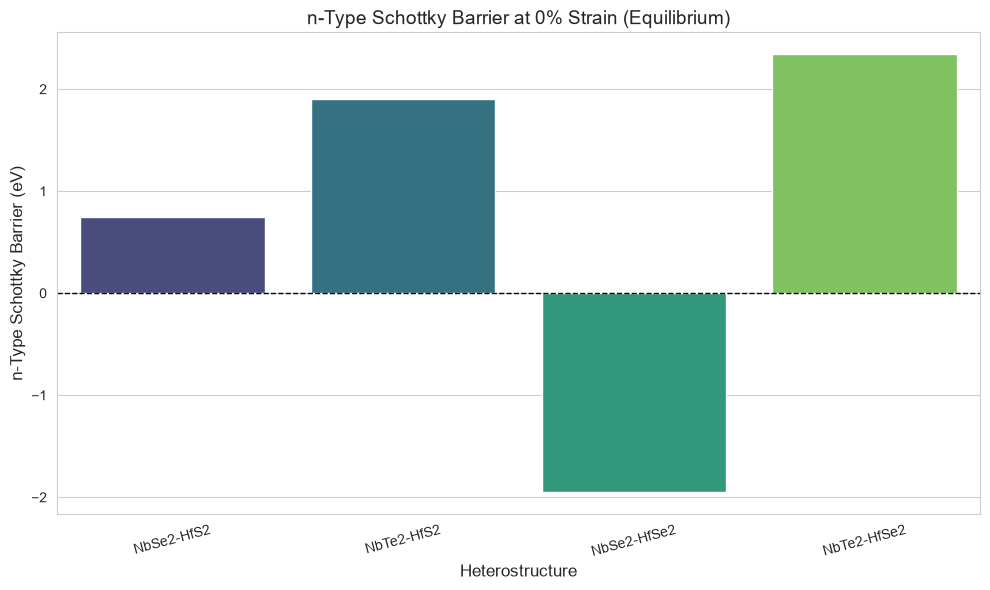

In [15]:
# Let's compare the materials at their unstrained (equilibrium) state.
# This is a simple bar chart, but it is very effective for a direct comparison.

# First, filter the data for 0% strain
df_equilibrium = df_all[df_all['strain_percent'] == 0]

# Create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='material', y='schottky_barrier_n_eV', data=df_equilibrium, palette='viridis')
plt.title('n-Type Schottky Barrier at 0% Strain (Equilibrium)', fontsize=14)
plt.xlabel('Heterostructure', fontsize=12)
plt.ylabel('n-Type Schottky Barrier (eV)', fontsize=12)
plt.xticks(rotation=15)

# Add a horizontal line at zero for reference
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

##### Explanation: This bar chart clearly shows that NbSe₂-HfS₂ has the lowest barrier at equilibrium (~0.75 eV), making it the most promising candidate for an Ohmic contact even before strain is applied. NbTe₂-HfS₂ has the highest barrier (~1.90 eV), requiring significant strain to achieve an Ohmic contact. This is a straightforward, powerful comparison.



#### Markdown Cell 8: Findings and Conclusion

##### Key Findings

1.  **Strain Engineering for Ohmic Contacts:** The most significant finding is that tensile strain can be used to tune the n-type Schottky barrier towards zero. For **NbSe₂-HfS₂**, an Ohmic contact is achieved at approximately **8% tensile strain**. For **NbTe₂-HfS₂**, the barrier is reduced but does not reach zero in the simulated strain range.
2.  **Correlation:** There is a clear negative correlation between tensile strain and the n-type Schottky barrier height. This confirms that strain is an effective tool for contact engineering.
3.  **Material Dependence:** The response to strain is highly material-dependent. The selenide-based heterostructures (NbSe₂-HfSe₂) show a different trend than the sulfide-based ones. This highlights the importance of careful material selection for specific device applications.

##### Conclusion

This EDA project successfully demonstrated how Python can be used to analyze and visualize DFT results for 2D materials. The plots clearly show the potential of strain engineering for designing low-resistance Ohmic contacts, which is a critical challenge in nanoelectronics.